# 01 · Exploring UK-DALE — what do appliance "jumps" look like?

**Goal of this notebook:** before any AI, just *look* at real data. We load one UK home (House 2), plot a day of its total power, and see how individual appliances show up inside it.

**How to use a notebook:** each grey box is a "cell". Click a cell and press **Shift + Enter** to run it — the result appears right underneath. Run them top to bottom, in order.

**The data, in one sentence:** researchers put a meter on the whole house *and* a smart plug on each appliance, and wrote down the power every 6 seconds for months. So we have the "answer key" for which appliance was on when.

## Step 1 — Tell Python where the data is

Change `DATA_DIR` if you saved UK-DALE somewhere else. The code then hunts for the `house_2` folder inside it, so it doesn't matter if the zip added an extra folder layer.

In [26]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(r"C:\Users\yazan\datasets\ukdale")   # <- where you put UK-DALE
HOUSE = 2

def find_house(data_dir, house):
    matches = [p for p in data_dir.rglob(f"house_{house}") if p.is_dir()]
    if not matches:
        raise FileNotFoundError(f"No 'house_{house}' folder found under {data_dir}. Did the unzip finish?")
    return matches[0]

house_dir = find_house(DATA_DIR, HOUSE)
print("Found:", house_dir)
print("Files:", len(list(house_dir.glob("*.dat"))), ".dat files")

Found: C:\Users\yazan\datasets\ukdale\house_2
Files: 32 .dat files


## Step 2 — Which meter is which appliance?

Each appliance has its own file: `channel_1.dat`, `channel_2.dat`, … The file `labels.dat` is the key that says which channel is which. **Channel 1 is always the whole house** ("aggregate") — that's the one that looks like what *your* plug will see.

In [27]:
labels = pd.read_csv(house_dir / "labels.dat", sep=" ", header=None, names=["channel", "appliance"])
labels = dict(zip(labels["appliance"], labels["channel"]))   # e.g. {"kettle": 8, ...}
for name, ch in labels.items():
    print(f"channel {ch:>2} -> {name}")

channel  1 -> aggregate
channel  2 -> laptop
channel  3 -> monitor
channel  4 -> speakers
channel  5 -> server
channel  6 -> router
channel  7 -> server_hdd
channel  8 -> kettle
channel  9 -> rice_cooker
channel 10 -> running_machine
channel 11 -> laptop2
channel 12 -> washing_machine
channel 13 -> dish_washer
channel 14 -> fridge
channel 15 -> microwave
channel 16 -> toaster
channel 17 -> playstation
channel 18 -> modem
channel 19 -> cooker


## Step 3 — Load a meter

Every line of a `.dat` file is just two numbers: **time** and **watts**. Time is a "Unix timestamp" — seconds since 1 Jan 1970 — which computers love and humans can't read, so we convert it to a normal UK date and time.

(The whole-house file is a few million lines. Loading takes a few seconds — that's normal.)

In [28]:
def load_channel(appliance):
    path = house_dir / f"channel_{labels[appliance]}.dat"
    df = pd.read_csv(path, sep=" ", header=None, names=["t", "watts"], usecols=[0, 1])
    df.index = pd.to_datetime(df["t"], unit="s", utc=True).dt.tz_convert("Europe/London")
    return df["watts"]

house = load_channel("aggregate")
print(f"{len(house):,} readings, from {house.index[0]:%d %b %Y} to {house.index[-1]:%d %b %Y}")
house.head()

2,780,373 readings, from 17 Feb 2013 to 10 Oct 2013


t
2013-02-17 16:17:34+00:00    340
2013-02-17 16:17:40+00:00    341
2013-02-17 16:17:46+00:00    347
2013-02-17 16:17:52+00:00    350
2013-02-17 16:17:58+00:00    342
Name: watts, dtype: int64

## Step 4 — Pick a busy day

Instead of picking a random (maybe boring) day, we pick the day the kettle was used the most — **but only among days when all the appliance meters we want to compare were recording.** (Real-world catch: in a months-long study, meters get added late, unplugged, or break. The first version of this notebook picked a day before the fridge meter existed!)

You can type your own date into `DAY` instead, e.g. `DAY = "2013-06-15"`.

In [29]:
SHOW = ["kettle", "cooker", "running_machine", "rice_cooker"]
SHOW = [a for a in SHOW if a in labels]          # skip any this house doesn't have

meters = {name: load_channel(name) for name in SHOW}   # load each appliance meter once
kettle = meters["kettle"]

# Which days did EVERY one of these meters record something?
days_each = [set(m.index.date) for m in meters.values()]
days_all = set.intersection(*days_each)
print(f"{len(days_all)} days where all {len(SHOW)} meters were recording")

DAY = "2013-09-01"
if DAY is None:
    kettle_on = kettle[kettle > 1000]                       # kettle is ~2-3 kW when on
    boils_per_day = kettle_on.groupby(kettle_on.index.date).size()
    candidates = boils_per_day[boils_per_day.index.isin(days_all)]
    DAY = (candidates if len(candidates) else boils_per_day).idxmax()
DAY = pd.Timestamp(DAY).strftime("%Y-%m-%d")
print("Day:", DAY)

def one_day(series, day=DAY):
    # Keep only readings from that calendar day (UK time).
    # Returns an empty series (instead of crashing) if this meter wasn't recording that day.
    start = pd.Timestamp(day, tz="Europe/London")
    end = start + pd.Timedelta(days=1)
    return series[(series.index >= start) & (series.index < end)]

126 days where all 4 meters were recording
Day: 2013-09-01


## Step 5 — The whole house for one day

This is what a NILM system "hears": one line, everything mixed together. Look for **tall thin spikes** (short, powerful things — kettle, toaster) and **a low wobbly floor** (things always on — fridge, router).

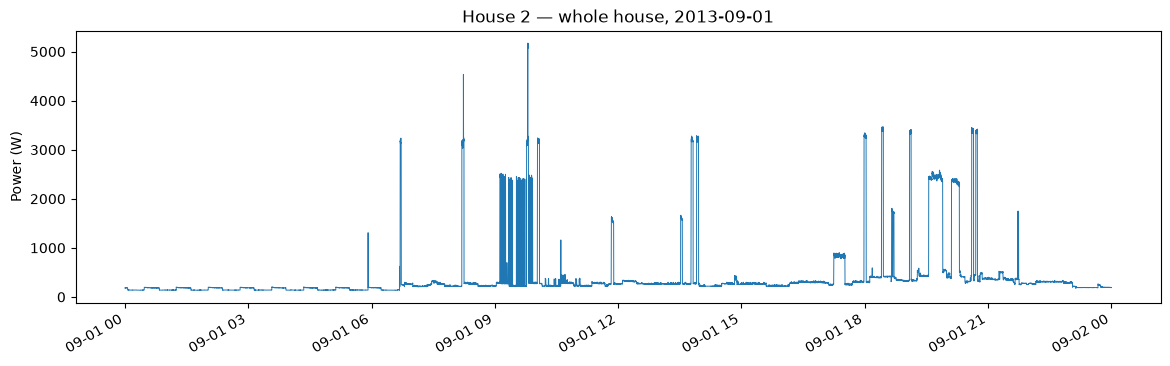

In [30]:
fig, ax = plt.subplots(figsize=(14, 4))
one_day(house).plot(ax=ax, lw=0.7)
ax.set_title(f"House {HOUSE} — whole house, {DAY}")
ax.set_ylabel("Power (W)")
ax.set_xlabel("")
plt.show()

## Step 6 — Now with the answer key

Same day, but each panel below is one appliance's own meter. Compare their spikes with the top panel: **every spike in the house line is made of one of these.** Teaching a model to do that matching by itself is the whole game.

(If you pick your own `DAY` and a panel says *"no recording on this day"*, that meter wasn't recording then.)

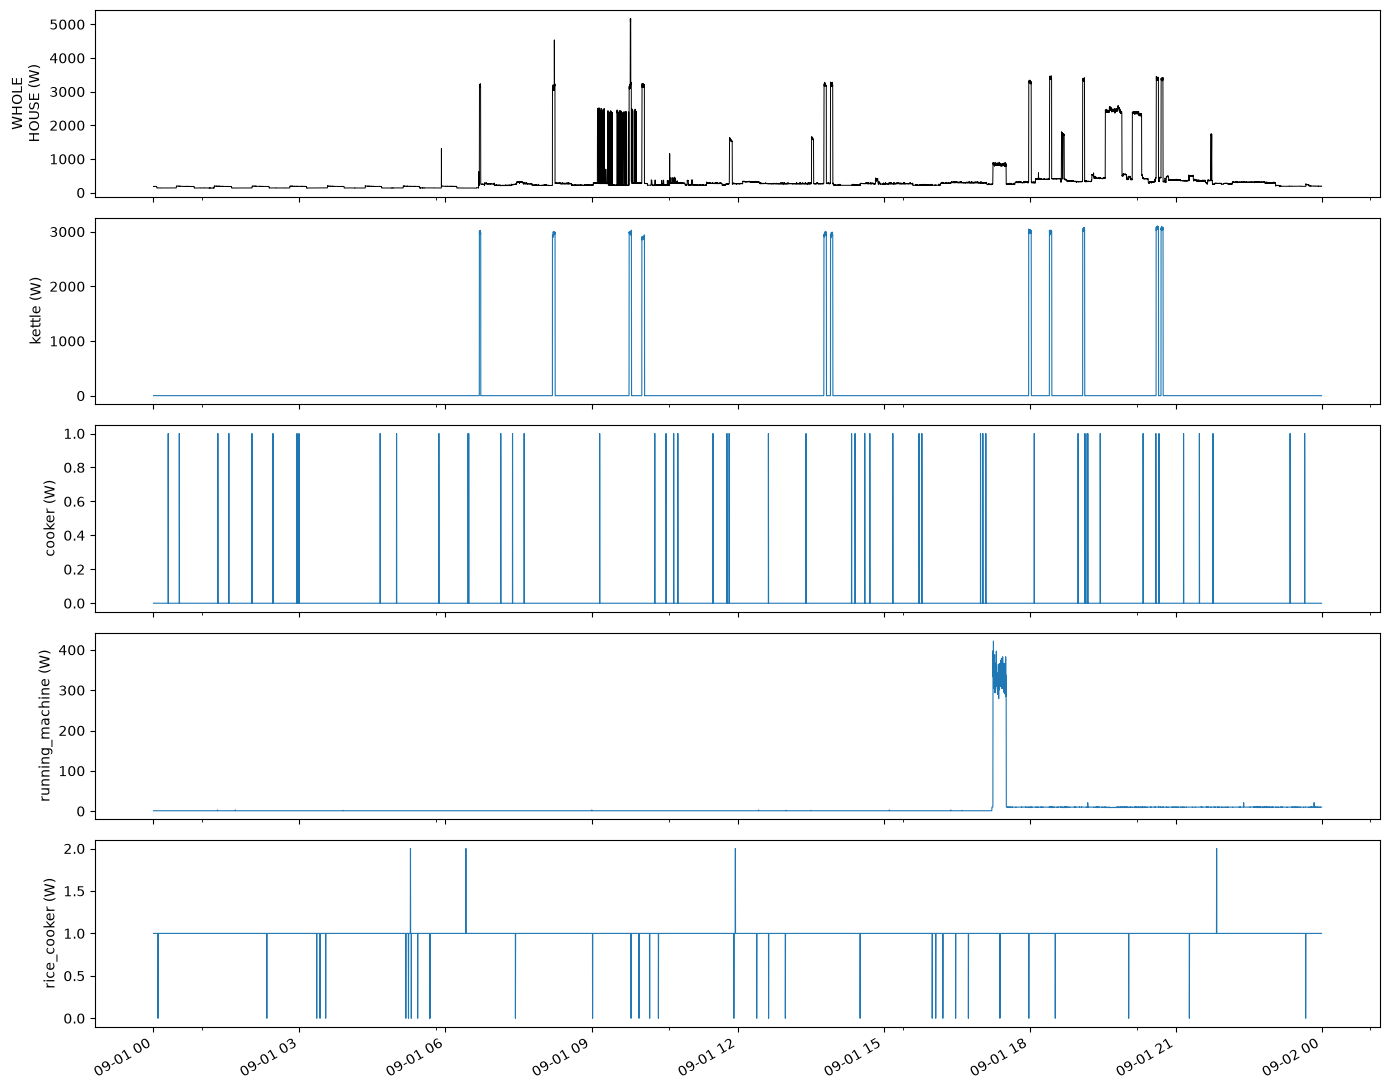

In [31]:
fig, axes = plt.subplots(len(SHOW) + 1, 1, figsize=(14, 2.2 * (len(SHOW) + 1)), sharex=True)
one_day(house).plot(ax=axes[0], lw=0.7, color="black")
axes[0].set_ylabel("WHOLE\nHOUSE (W)")
for ax, name in zip(axes[1:], SHOW):
    data = one_day(meters[name])
    if data.empty:   # this meter wasn't recording on this day
        ax.text(0.5, 0.5, "no recording on this day", transform=ax.transAxes, ha="center", va="center", color="grey")
    else:
        data.plot(ax=ax, lw=0.8)
    ax.set_ylabel(f"{name} (W)")
axes[-1].set_xlabel("")
plt.tight_layout()
plt.show()

## Step 7 — Zoom in on one kettle boil

A kettle is a near-perfect "fingerprint": the house power jumps **up by ~2–3 kW in one step**, stays flat for a few minutes, then drops by the same amount.

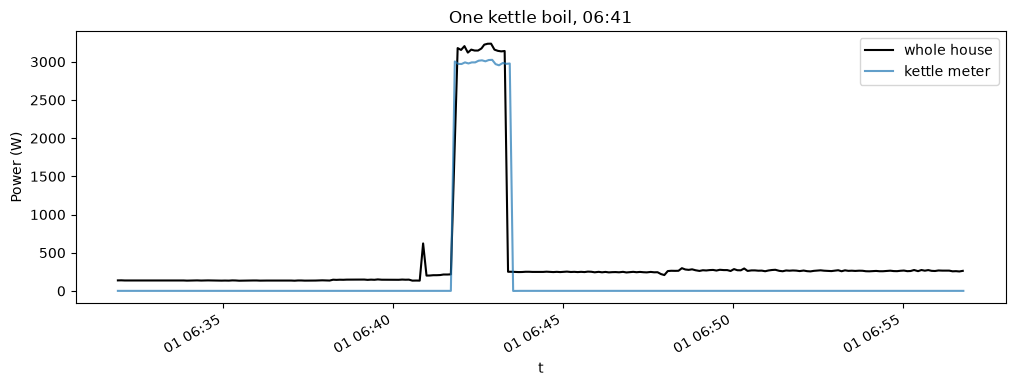

In [32]:
day_kettle = one_day(kettle)
start = day_kettle[day_kettle > 1000].index[0]          # first boil of the day
window = slice(start - pd.Timedelta("10min"), start + pd.Timedelta("15min"))

fig, ax = plt.subplots(figsize=(12, 4))
house.loc[window].plot(ax=ax, label="whole house", color="black")
kettle.loc[window].plot(ax=ax, label="kettle meter", alpha=0.7)
ax.set_title(f"One kettle boil, {start:%H:%M}")
ax.set_ylabel("Power (W)")
ax.legend()
plt.show()

## Step 8 — Turning the picture into numbers: "jumps"

The model won't look at pictures. Instead, for every reading we ask: **how much did the power change since the last reading?** Big positive number = something switched on; big negative = something switched off. These are the *events* our model will learn to label in the next notebook.

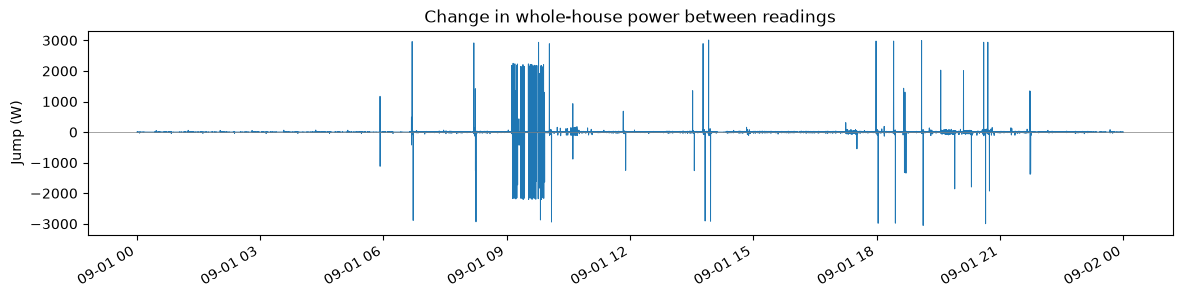

110 jumps bigger than 500 W on 2013-09-01. The first 15:
t
2013-09-01 05:55:00+01:00    1170.0
2013-09-01 05:55:07+01:00   -1119.0
2013-09-01 06:41:54+01:00    2962.0
2013-09-01 06:43:23+01:00   -2890.0
2013-09-01 08:11:54+01:00    2917.0
2013-09-01 08:14:10+01:00    1419.0
2013-09-01 08:14:16+01:00   -1260.0
2013-09-01 08:15:04+01:00   -2934.0
2013-09-01 09:07:18+01:00    2181.0
2013-09-01 09:08:24+01:00   -2174.0
2013-09-01 09:09:14+01:00    2250.0
2013-09-01 09:09:32+01:00   -2157.0
2013-09-01 09:10:21+01:00    2140.0
2013-09-01 09:10:28+01:00   -2163.0
2013-09-01 09:11:48+01:00    2233.0


In [33]:
day_house = one_day(house)
jump = day_house.diff()            # change from previous reading

fig, ax = plt.subplots(figsize=(14, 3))
jump.plot(ax=ax, lw=0.7)
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Change in whole-house power between readings")
ax.set_ylabel("Jump (W)")
ax.set_xlabel("")
plt.show()

big = jump[jump.abs() > 500].round()
print(f"{len(big)} jumps bigger than 500 W on {DAY}. The first 15:")
print(big.head(15).to_string())

## What we learned

- The whole-house line is a **mix**; the appliance meters are the **answer key**.
- Appliances switching on/off show up as **sudden jumps**. A kettle is a clean +2–3 kW step; a fridge is a small (~100 W) repeating bump.
- So the plan for the next notebook: **find every jump → describe it with a few numbers (size, how long it lasts, time of day) → check the answer key for which appliance caused it → train a model on that.**

✏️ *Try it:* change `DAY`, or put `"laptop"` or `"rice_cooker"` into `SHOW` (Step 4), and rerun from Step 4.